# EDA

Requiere haber corrido `descarga.ipynb` antes (dataset ya en `data/`). Este notebook:

1. Parsea todos los `.txt` de labels a un DataFrame: `imagen, split, clase, area_relativa, aspect_ratio`, junto con la resolución y el formato de cada imagen.
2. Tabla de composición por categoría (solo fuego / solo humo / ambos / none) por split.
3. Resolución, relación de aspecto y formato de las imágenes.
4. Área relativa por clase y tamaño en píxeles tras el letterbox a 640 y 960: evidencia para **H1** (el fuego incipiente ocupa pocos píxeles).
5. Relación de aspecto de las cajas.
6. Distribución de cajas por imagen.
7. Conteo de negativos por split.
8. Duplicados exactos y casi-duplicados entre splits.

Todas las figuras se guardan en `figures/` en PDF (vectorial, para el paper) y PNG.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}
REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLASS_COLORS = {"fire": "tab:red", "smoke": "tab:gray"}

# Números oficiales de D-Fire (paper original)
OFFICIAL_CATEGORIES = {"solo_fuego": 1164, "solo_humo": 5867, "ambos": 4658, "none": 9838}
OFFICIAL_BOXES = {"fire": 14692, "smoke": 11865}

def save(fig, name: str):
    """Guarda la figura en PDF (vectorial, para el paper) y PNG."""
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=150, bbox_inches="tight")

## 0. Orden de clases

Verificado en `descarga.ipynb` (sección 6) contra los totales oficiales de cajas y con inspección visual (`figures/verificacion_clases.png`).

In [2]:
CLASS_NAMES = {
    0: "smoke",
    1: "fire",
}

## 1. Ubicar splits

Misma detección automática que en `descarga.ipynb`, corrida sobre `data/` (el dataset ya descargado).

In [3]:
def find_split_dirs(root: Path):
    candidates = {"train": [], "val": [], "valid": [], "test": []}
    for p in root.rglob("*"):
        if p.is_dir() and p.name.lower() in candidates:
            candidates[p.name.lower()].append(p)
    return candidates

split_candidates = find_split_dirs(DATA_DIR)
SPLIT_DIRS = {
    "train": split_candidates["train"][0] if split_candidates["train"] else None,
    "val": (split_candidates["val"] or split_candidates["valid"] or [None])[0],
    "test": split_candidates["test"][0] if split_candidates["test"] else None,
}
SPLIT_DIRS

{'train': WindowsPath('C:/Proyectos/CV2/detección_incendios/data/data/train'),
 'val': WindowsPath('C:/Proyectos/CV2/detección_incendios/data/data/val'),
 'test': WindowsPath('C:/Proyectos/CV2/detección_incendios/data/data/test')}

## 2. Parseo de labels a DataFrame

- `df`: una fila por bounding box (`imagen, split, clase, w, h, area_relativa, aspect_ratio`, más el tamaño de la imagen). Las imágenes sin objetos ("none") quedan con una única fila con `clase` vacía.
- `df_img`: una fila por imagen con resolución, formato real (según el contenido, no la extensión) y modo de color.

`aspect_ratio` se calcula en píxeles, `(w · ancho) / (h · alto)`: en coordenadas normalizadas `w / h` sale deformado por la relación de aspecto de la imagen (en 1280×720 una caja cuadrada da 0,56).

In [4]:
def parse_split(split: str, split_dir: Path) -> tuple[list[dict], list[dict]]:
    images = sorted(p for p in split_dir.rglob("*") if p.suffix.lower() in IMAGE_EXTS)
    label_index = {p.stem: p for p in split_dir.rglob("*.txt")}

    box_rows, img_rows = [], []
    for img_path in images:
        with Image.open(img_path) as im:
            W, H = im.size
            img_rows.append({
                "imagen": img_path.name, "split": split, "ruta": img_path,
                "ancho_px": W, "alto_px": H,
                "extension": img_path.suffix.lower(), "formato": im.format, "modo": im.mode,
            })

        label_path = label_index.get(img_path.stem)
        text = label_path.read_text().strip() if label_path is not None else ""
        base = {"imagen": img_path.name, "split": split, "ancho_img": W, "alto_img": H}

        if not text:
            box_rows.append({**base, "clase": None})
            continue

        for line in text.splitlines():
            cls_idx, _, _, w, h = (float(x) for x in line.split()[:5])
            box_rows.append({
                **base,
                "clase": CLASS_NAMES.get(int(cls_idx), int(cls_idx)),
                "w": w,
                "h": h,
                "area_relativa": w * h,
                "aspect_ratio": (w * W) / (h * H) if h > 0 else np.nan,
            })
    return box_rows, img_rows

all_boxes, all_imgs = [], []
for split, split_dir in SPLIT_DIRS.items():
    if split_dir is None:
        print(f"[!] No se encontró carpeta para split '{split}'")
        continue
    box_rows, img_rows = parse_split(split, split_dir)
    all_boxes.extend(box_rows)
    all_imgs.extend(img_rows)

df = pd.DataFrame(all_boxes)
df_img = pd.DataFrame(all_imgs)

# Todas las cajas anotadas, y el subconjunto geométricamente válido (w, h > 0) para el análisis de tamaños
boxes_all = df.dropna(subset=["clase"])
boxes = boxes_all[(boxes_all["w"] > 0) & (boxes_all["h"] > 0)]

box_totals = boxes_all["clase"].value_counts().to_dict()
assert box_totals == OFFICIAL_BOXES, f"Cajas por clase {box_totals} != oficiales {OFFICIAL_BOXES}"
print(f"{len(df_img)} imágenes, {len(boxes_all)} cajas ({len(boxes_all) - len(boxes)} degeneradas excluidas del análisis geométrico)")
df.head()

21527 imágenes, 26557 cajas (18 degeneradas excluidas del análisis geométrico)


,imagen,split,ancho_img,alto_img,clase,w,h,area_relativa,aspect_ratio
0,AoF00000.jpg,train,1086,610,NaN,NaN,NaN,NaN,NaN
1,AoF00001.jpg,train,1103,598,fire,0.136899,0.150502,0.020604,1.677778
2,AoF00002.jpg,train,1087,604,smoke,0.036799,0.054636,0.002011,1.212121
3,AoF00003.jpg,train,1024,576,NaN,NaN,NaN,NaN,NaN
4,AoF00004.jpg,train,1280,720,NaN,NaN,NaN,NaN,NaN


## 3. Composición por categoría y split

Por imagen: `solo_fuego`, `solo_humo`, `ambos` o `none`, según el conjunto de clases presentes.

In [5]:
def categorize(classes: set) -> str:
    if not classes:
        return "none"
    if classes == {"fire"}:
        return "solo_fuego"
    if classes == {"smoke"}:
        return "solo_humo"
    return "ambos"

# dropna: pandas guarda la clase vacía de las imágenes "none" como NaN, no como None
img_category = (
    df.groupby(["split", "imagen"])["clase"]
    .apply(lambda s: categorize(set(s.dropna())))
    .rename("categoria")
    .reset_index()
)

composition = (
    img_category.groupby(["split", "categoria"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=["train", "val", "test"], columns=["solo_fuego", "solo_humo", "ambos", "none"])
)
composition["total"] = composition.sum(axis=1)
composition.loc["total"] = composition.sum()

for cat, n in OFFICIAL_CATEGORIES.items():
    assert composition.loc["total", cat] == n, f"{cat}: {composition.loc['total', cat]} != {n}"
composition

categoria,solo_fuego,solo_humo,ambos,none,total
split,,,,,
train,770,3836,3058,6458,14122
val,174,845,705,1375,3099
test,220,1186,895,2005,4306
total,1164,5867,4658,9838,21527


In [6]:
# Cajas por clase y split
boxes_split = pd.crosstab(boxes_all["split"], boxes_all["clase"]).reindex(["train", "val", "test"])
boxes_split.loc["total"] = boxes_split.sum()
boxes_split

clase,fire,smoke
split,,
train,9638,7794
val,2176,1756
test,2878,2315
total,14692,11865


## 4. Resolución, relación de aspecto y formato de las imágenes

D-Fire **no** viene a 416×416: las imágenes conservan la resolución de su fuente (cámaras de vigilancia, simulaciones, internet). Esto importa para el preprocesamiento (letterbox) y para H1: el área relativa sola no dice cuántos píxeles le llegan al modelo.

In [7]:
res = (
    df_img.groupby(["ancho_px", "alto_px"]).size().rename("n_imagenes")
    .sort_values(ascending=False).to_frame()
)
res["pct"] = (res["n_imagenes"] / len(df_img) * 100).round(1)
print("Resoluciones distintas:", len(res))
res.head(10)

Resoluciones distintas: 3366


,,n_imagenes,pct
ancho_px,alto_px,,
1280,720,9167,42.6
640,360,4132,19.2
480,360,748,3.5
640,352,688,3.2
1920,1080,276,1.3
540,360,258,1.2
768,432,137,0.6
800,450,131,0.6
640,480,126,0.6


In [8]:
# Formato real según el contenido vs. extensión del archivo
df_img.groupby(["extension", "formato", "modo"]).size().rename("n_imagenes").to_frame()

n_imagenes
extension formato modo            
.jpg      JPEG    RGB        21473
          PNG     RGB            6
                  RGBA          48

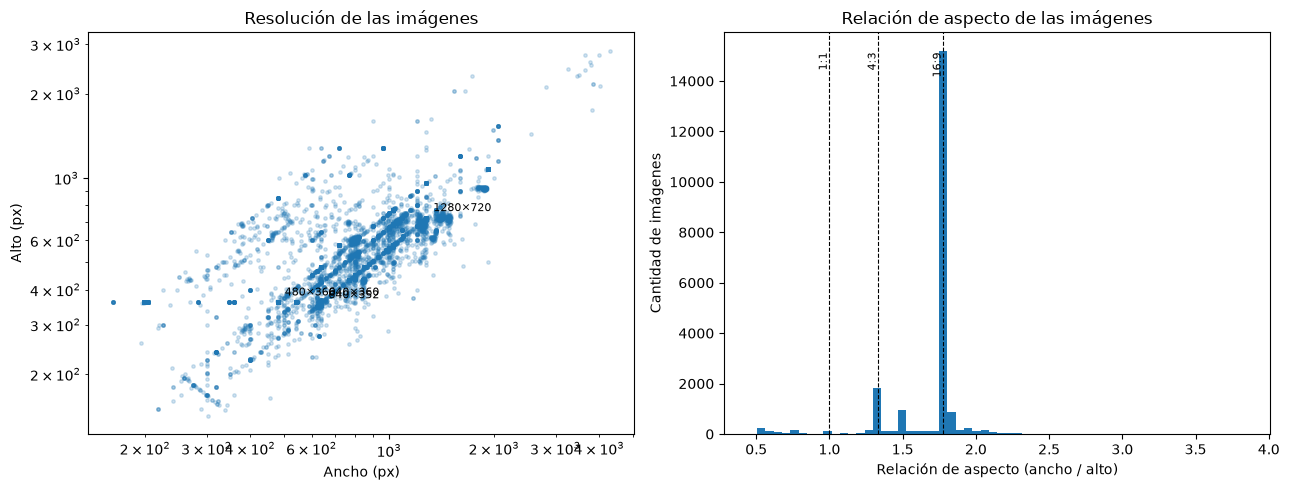

In [9]:
df_img["aspect_img"] = df_img["ancho_px"] / df_img["alto_px"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(df_img["ancho_px"], df_img["alto_px"], s=6, alpha=0.2, color="tab:blue")
for ancho, alto in res.head(4).index:
    ax.annotate(f"{ancho}×{alto}", (ancho, alto), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Ancho (px)")
ax.set_ylabel("Alto (px)")
ax.set_title("Resolución de las imágenes")

ax = axes[1]
ax.hist(df_img["aspect_img"], bins=60, color="tab:blue")
for ar, label in ((16 / 9, "16:9"), (4 / 3, "4:3"), (1, "1:1")):
    ax.axvline(ar, color="k", ls="--", lw=0.8)
    ax.text(ar, ax.get_ylim()[1] * 0.95, label, rotation=90, va="top", ha="right", fontsize=8)
ax.set_xlabel("Relación de aspecto (ancho / alto)")
ax.set_ylabel("Cantidad de imágenes")
ax.set_title("Relación de aspecto de las imágenes")
fig.tight_layout()
save(fig, "resolucion_imagenes")

## 5. Área relativa por clase, evidencia H1

H1: el fuego incipiente ocupa pocos píxeles; se espera que `fire` concentre más masa en áreas relativas chicas que `smoke`.

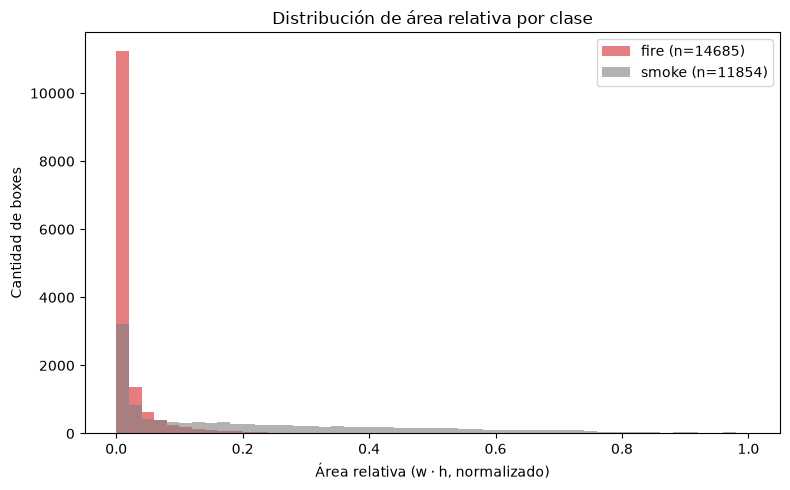

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
for clase, color in CLASS_COLORS.items():
    subset = boxes.loc[boxes["clase"] == clase, "area_relativa"]
    ax.hist(subset, bins=50, range=(0, 1), alpha=0.6, label=f"{clase} (n={len(subset)})", color=color)

ax.set_xlabel("Área relativa (w · h, normalizado)")
ax.set_ylabel("Cantidad de boxes")
ax.set_title("Distribución de área relativa por clase")
ax.legend()
fig.tight_layout()
save(fig, "area_relativa")

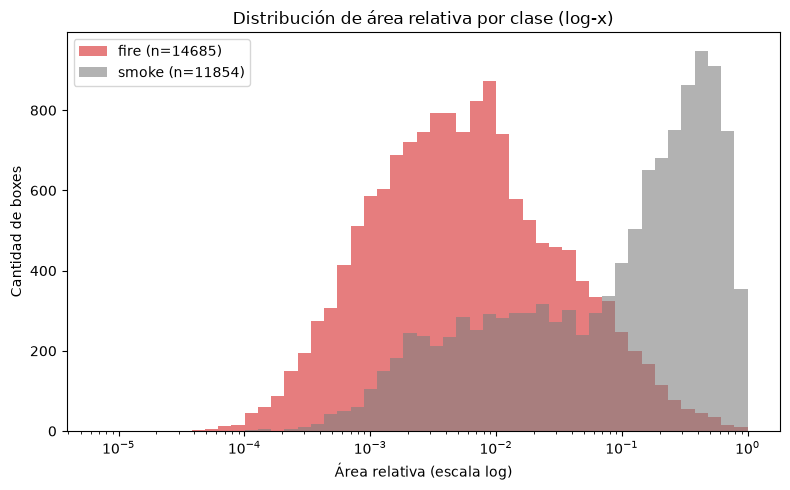

In [11]:
# Misma distribución en escala log (bins logarítmicos), para ver mejor la cola de objetos chicos
log_bins = np.logspace(np.log10(boxes["area_relativa"].min()), 0, 50)

fig, ax = plt.subplots(figsize=(8, 5))
for clase, color in CLASS_COLORS.items():
    subset = boxes.loc[boxes["clase"] == clase, "area_relativa"]
    ax.hist(subset, bins=log_bins, alpha=0.6, label=f"{clase} (n={len(subset)})", color=color)

ax.set_xscale("log")
ax.set_xlabel("Área relativa (escala log)")
ax.set_ylabel("Cantidad de boxes")
ax.set_title("Distribución de área relativa por clase (log-x)")
ax.legend()
fig.tight_layout()
save(fig, "area_relativa_log")

In [12]:
# Cuantiles de área relativa por clase
boxes.groupby("clase")["area_relativa"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])

,count,mean,std,min,10%,25%,50%,75%,90%,max
clase,,,,,,,,,,
fire,14685.0,0.024433,0.061735,0.000007,0.000652,0.001656,0.005391,0.018313,0.060694,0.963108
smoke,11854.0,0.226392,0.241279,0.000039,0.003256,0.016281,0.142450,0.379061,0.601662,1.000000


### Tamaño en píxeles tras el letterbox (640 y 960)

Lo que ve el modelo es la caja después de reescalar la imagen para que el lado mayor mida `imgsz`. Calculamos el área de cada caja en esa escala y la clasificamos con los umbrales COCO: **small** < 32², **medium** < 96², **large** ≥ 96² px. Si H1 se cumple, `fire` debería tener más proporción de cajas small que `smoke`, y pasar de 640 a 960 debería sacar más cajas de fuego de la categoría small.

In [13]:
IMGSZ = (640, 960)
SMALL, MEDIUM = 32**2, 96**2  # umbrales COCO

def area_px(boxes: pd.DataFrame, imgsz: int) -> pd.Series:
    scale = imgsz / boxes[["ancho_img", "alto_img"]].max(axis=1)
    return (boxes["w"] * boxes["ancho_img"] * scale) * (boxes["h"] * boxes["alto_img"] * scale)

size_tables = []
for imgsz in IMGSZ:
    a = area_px(boxes, imgsz)
    tam = pd.cut(a, [0, SMALL, MEDIUM, np.inf], labels=["small_%", "medium_%", "large_%"], right=False)
    t = pd.crosstab(boxes["clase"], tam, normalize="index").mul(100).round(1).rename_axis(columns=None)
    t["mediana_lado_px"] = np.sqrt(a).groupby(boxes["clase"]).median().round(1)
    t.insert(0, "imgsz", imgsz)
    size_tables.append(t)

size_table = pd.concat(size_tables).reset_index().set_index(["imgsz", "clase"])
size_table

small_%  medium_%  large_%  mediana_lado_px
imgsz clase                                             
640   fire      45.0      40.0     15.0             35.9
      smoke     12.2      21.4     66.4            186.0
960   fire      27.7      46.2     26.0             53.9
      smoke      5.8      19.8     74.4            278.9

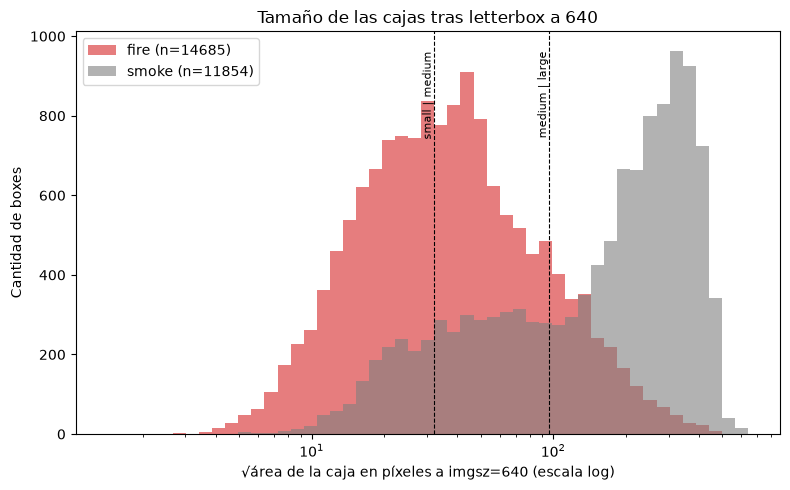

In [14]:
side_640 = np.sqrt(area_px(boxes, 640))
bins = np.logspace(np.log10(side_640.min()), np.log10(640), 50)

fig, ax = plt.subplots(figsize=(8, 5))
for clase, color in CLASS_COLORS.items():
    subset = side_640[boxes["clase"] == clase]
    ax.hist(subset, bins=bins, alpha=0.6, label=f"{clase} (n={len(subset)})", color=color)
for thr, label in ((32, "small | medium"), (96, "medium | large")):
    ax.axvline(thr, color="k", ls="--", lw=0.8)
    ax.text(thr, ax.get_ylim()[1] * 0.95, label, rotation=90, va="top", ha="right", fontsize=8)

ax.set_xscale("log")
ax.set_xlabel("√área de la caja en píxeles a imgsz=640 (escala log)")
ax.set_ylabel("Cantidad de boxes")
ax.set_title("Tamaño de las cajas tras letterbox a 640")
ax.legend()
fig.tight_layout()
save(fig, "tamano_cajas_px_640")

## 6. Relación de aspecto de las cajas

En píxeles (`ancho / alto` de la caja). > 1 es una caja apaisada, < 1 una caja vertical.

,count,mean,std,min,10%,50%,90%,max
clase,,,,,,,,
fire,14685.0,1.718767,1.318632,0.145631,0.734303,1.376812,3.000000,29.086957
smoke,11854.0,1.720615,0.955602,0.247312,0.760870,1.524828,2.847908,10.684211


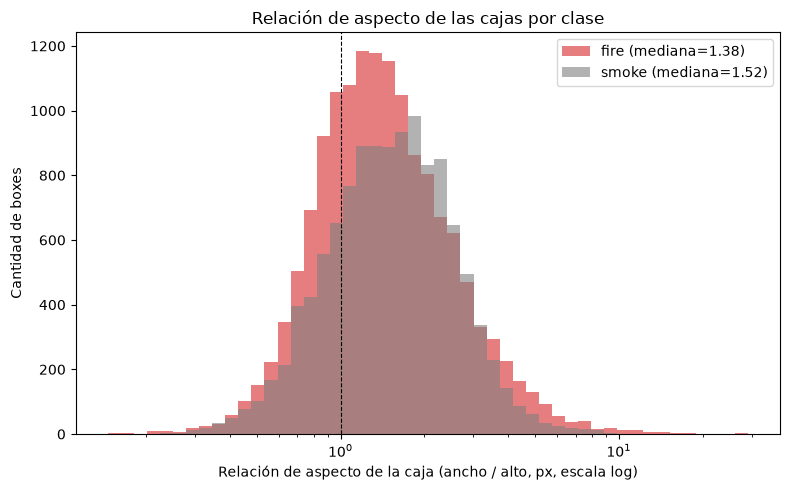

In [15]:
ar_bins = np.logspace(np.log10(boxes["aspect_ratio"].min()), np.log10(boxes["aspect_ratio"].max()), 50)

fig, ax = plt.subplots(figsize=(8, 5))
for clase, color in CLASS_COLORS.items():
    subset = boxes.loc[boxes["clase"] == clase, "aspect_ratio"]
    ax.hist(subset, bins=ar_bins, alpha=0.6, label=f"{clase} (mediana={subset.median():.2f})", color=color)
ax.axvline(1, color="k", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("Relación de aspecto de la caja (ancho / alto, px, escala log)")
ax.set_ylabel("Cantidad de boxes")
ax.set_title("Relación de aspecto de las cajas por clase")
ax.legend()
fig.tight_layout()
save(fig, "aspect_ratio_cajas")

boxes.groupby("clase")["aspect_ratio"].describe(percentiles=[0.1, 0.5, 0.9])

## 7. Distribución de cajas por imagen

count    11689.000000
mean         2.271965
std          1.959384
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max         23.000000
Name: n_boxes, dtype: float64

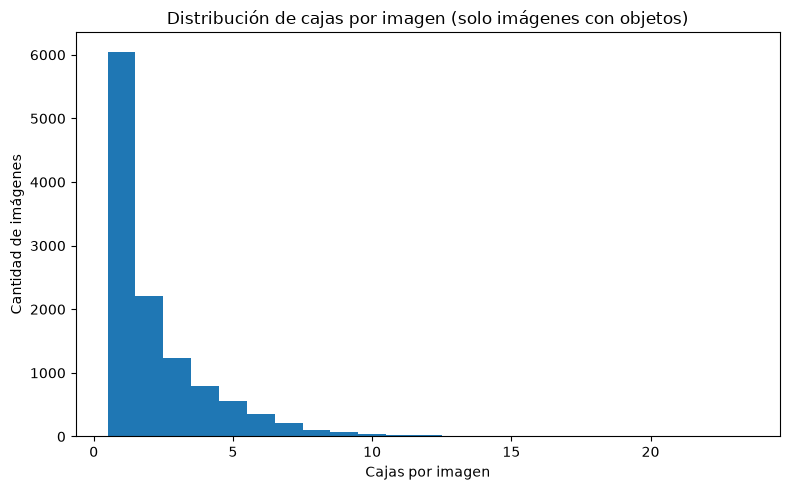

In [16]:
boxes_per_image = (
    boxes_all.groupby(["split", "imagen"]).size().rename("n_boxes").reset_index()
)

fig, ax = plt.subplots(figsize=(8, 5))
max_boxes = int(boxes_per_image["n_boxes"].max())
ax.hist(
    boxes_per_image["n_boxes"],
    bins=range(1, max_boxes + 2),
    align="left",
    color="tab:blue",
)
ax.set_xlabel("Cajas por imagen")
ax.set_ylabel("Cantidad de imágenes")
ax.set_title("Distribución de cajas por imagen (solo imágenes con objetos)")
fig.tight_layout()
save(fig, "cajas_por_imagen")

boxes_per_image["n_boxes"].describe()

## 8. Conteo de negativos por split

In [17]:
negatives = (
    img_category[img_category["categoria"] == "none"]
    .groupby("split")
    .size()
    .rename("n_negativos")
)
totals = img_category.groupby("split").size().rename("n_total")

neg_table = pd.concat([negatives, totals], axis=1).fillna(0).reindex(["train", "val", "test"])
neg_table["pct_negativos"] = (neg_table["n_negativos"] / neg_table["n_total"] * 100).round(1)
assert neg_table["n_negativos"].sum() == OFFICIAL_CATEGORIES["none"]
neg_table

,n_negativos,n_total,pct_negativos
split,,,
train,6458,14122,45.7
val,1375,3099,44.4
test,2005,4306,46.6


## 9. Duplicados entre splits

El split oficial separa por imagen, pero D-Fire incluye frames de video: dos frames consecutivos son casi idénticos aunque sus bytes no lo sean. Si un frame está en train y su vecino en test, el test mide memoria y no generalización.

- **Duplicados exactos:** MD5 de los bytes del archivo.
- **Casi-duplicados:** *difference hash* (dHash) de 64 bits sobre la imagen reducida a 9×8 en escala de grises. Para cada imagen de val/test buscamos la de train (y de test contra val) con menor distancia de Hamming. Distancia 0–4 sobre 64 bits es, en la práctica, la misma escena.

In [18]:
def dhash(path: Path, size: int = 8) -> int:
    with Image.open(path) as im:
        im.draft("L", (size * 8, size * 8))  # decodificación JPEG reducida: mucho más rápido
        g = np.asarray(im.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return int.from_bytes(np.packbits(bits).tobytes(), "big")

df_img["md5"] = [hashlib.md5(p.read_bytes()).hexdigest() for p in df_img["ruta"]]
df_img["dhash"] = [dhash(p) for p in df_img["ruta"]]

exact = df_img.groupby("md5")["split"].nunique()
print("Duplicados exactos entre splits:", int((exact > 1).sum()))
print("Imágenes con MD5 repetido (cualquier split):", int(df_img["md5"].duplicated(keep=False).sum()))

Duplicados exactos entre splits: 0
Imágenes con MD5 repetido (cualquier split): 0


In [19]:
POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def nearest_hamming(query: np.ndarray, ref: np.ndarray, chunk: int = 256):
    """Para cada hash de `query`, distancia de Hamming mínima contra `ref` y su índice."""
    dist = np.empty(len(query), dtype=np.int64)
    idx = np.empty(len(query), dtype=np.int64)
    for s in range(0, len(query), chunk):
        x = query[s:s + chunk, None] ^ ref[None, :]
        d = POPCOUNT[x.view(np.uint8)].reshape(x.shape + (8,)).sum(-1)
        dist[s:s + chunk] = d.min(1)
        idx[s:s + chunk] = d.argmin(1)
    return dist, idx

hashes = {s: df_img.loc[df_img["split"] == s, "dhash"].to_numpy(dtype=np.uint64) for s in ("train", "val", "test")}
names = {s: df_img.loc[df_img["split"] == s, "imagen"].to_numpy() for s in ("train", "val", "test")}

THRESHOLDS = (0, 2, 4, 8)
near_rows, near_pairs = [], []
for query, ref in (("val", "train"), ("test", "train"), ("test", "val")):
    dist, idx = nearest_hamming(hashes[query], hashes[ref])
    row = {"query": query, "ref": ref, "n_query": len(dist)}
    for t in THRESHOLDS:
        row[f"d<={t}"] = int((dist <= t).sum())
        row[f"d<={t}_%"] = round((dist <= t).mean() * 100, 1)
    near_rows.append(row)
    near_pairs.append(pd.DataFrame({
        "query_split": query, "query": names[query], "ref_split": ref, "ref": names[ref][idx], "dist": dist,
    }))

near_pairs = pd.concat(near_pairs, ignore_index=True)
near_table = pd.DataFrame(near_rows).set_index(["query", "ref"])
near_table

n_query  d<=0  d<=0_%  d<=2  d<=2_%  d<=4  d<=4_%  d<=8  d<=8_%
query ref                                                                   
val   train     3099   694    22.4  1261    40.7  1513    48.8  1966    63.4
test  train     4306   939    21.8  1739    40.4  2150    49.9  2770    64.3
      val       4306   487    11.3  1170    27.2  1601    37.2  2343    54.4

In [20]:
# ¿La fuga afecta a imágenes con fuego/humo o solo a negativos? Test vs train, por categoría de la imagen de test
test_vs_train = near_pairs[(near_pairs["query_split"] == "test") & (near_pairs["ref_split"] == "train")]
test_vs_train = test_vs_train.merge(
    img_category[img_category["split"] == "test"][["imagen", "categoria"]], left_on="query", right_on="imagen"
)
leak_by_cat = test_vs_train.groupby("categoria")["dist"].agg(
    n="size",
    **{f"d<={t}_%": (lambda d, t=t: round((d <= t).mean() * 100, 1)) for t in THRESHOLDS},
).reindex(["solo_fuego", "solo_humo", "ambos", "none"])
leak_by_cat

,n,d<=0_%,d<=2_%,d<=4_%,d<=8_%
categoria,,,,,
solo_fuego,220,29.5,46.4,57.7,72.3
solo_humo,1186,19.6,39.5,48.6,61.0
ambos,895,8.3,17.7,24.7,42.9
none,2005,28.3,50.4,61.1,75.0


### Lectura

Hay fuga real entre splits. En el split oficial, ~50 % de las imágenes de test tienen en train una imagen a distancia dHash ≤ 4, y ~22 % a distancia 0. Los ejemplos de arriba son la misma cámara fija, a segundos o días de diferencia. Afecta a las imágenes con humo o fuego (≈ 50–58 % de `solo_humo` y `solo_fuego` a d ≤ 4), no solo a los negativos.

Implicancias para el paper:

- Las métricas sobre el test oficial son **optimistas** respecto de una cámara nueva. Se reporta como limitación y se sigue usando el split oficial, para que los números sean comparables con la literatura.
- La evaluación sobre video propio (alerta) y el set de estrés externo **no** tienen esta fuga: son la medida honesta de generalización.

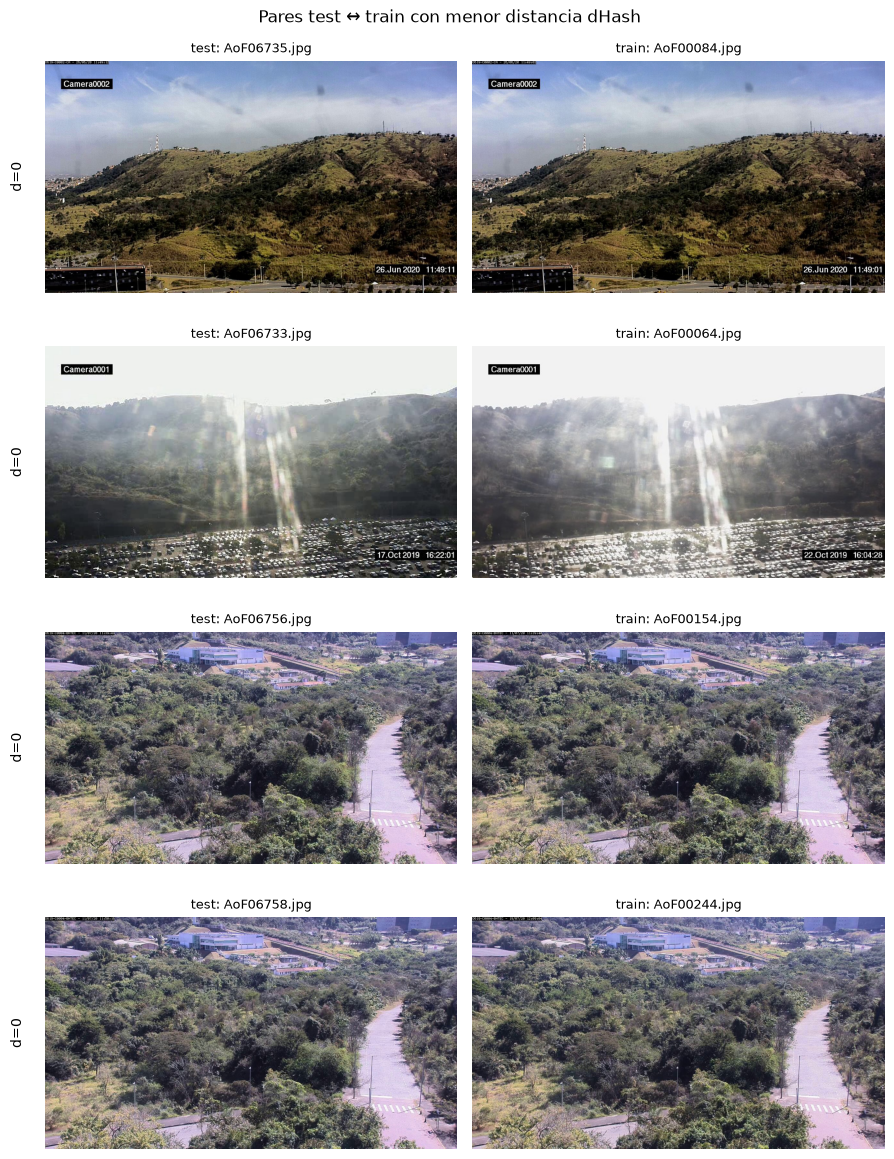

In [21]:
# Ejemplos de pares casi-duplicados test ↔ train (los de menor distancia)
rutas = df_img.set_index(["split", "imagen"])["ruta"]
examples = near_pairs[near_pairs["query_split"] == "test"].sort_values("dist").head(4)

fig, axes = plt.subplots(len(examples), 2, figsize=(9, 3 * len(examples)))
for (ax_q, ax_r), (_, r) in zip(axes, examples.iterrows()):
    for ax, split, name in ((ax_q, r["query_split"], r["query"]), (ax_r, r["ref_split"], r["ref"])):
        ax.imshow(Image.open(rutas[(split, name)]).convert("RGB"))
        ax.set_title(f"{split}: {name}", fontsize=9)
        ax.axis("off")
    ax_q.text(-0.05, 0.5, f"d={r['dist']}", transform=ax_q.transAxes, rotation=90, va="center", ha="right")
fig.suptitle("Pares test ↔ train con menor distancia dHash")
fig.tight_layout()
save(fig, "casi_duplicados_test_train")